# Imports

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [6]:
import torch
from torchinfo import summary
from torchview import draw_graph

from config import SCGPT_DIR, GENEFORMER_DIR, GENEFORMER_ASSETS
from models.scgpt import ScGPT
from models.geneformer import Geneformer


from IPython.display import Image, display

# Models

In [12]:
models = {
    "scGPT": ScGPT(SCGPT_DIR, device="cpu"),
    "Geneformer": Geneformer(
        GENEFORMER_DIR,
        GENEFORMER_ASSETS,
        device="cpu"
    ),
}

/home/rceccaroni/micromamba/envs/nw-huggingface/python/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:774: UserWarning: `return_dict_in_generate` is NOT set to `True`, but `output_hidden_states` is. When `return_dict_in_generate` is not `True`, `output_hidden_states` is ignored.
  warnings.warn(


# TorchInfo

In [6]:
for name, adapter in models.items():
    model = adapter.model

    print(f"\n{'=' * 60}")
    print(name)
    print(f"{'=' * 60}")

    summary(
        model,
        depth=3,
        col_names=["num_params", "trainable"],
    )

    total = sum(p.numel() for p in model.parameters())
    print(f"\nTotal parameters: {total:,}")
    print(f"Parameters (M): {total / 1e6:.2f}M")


scGPT

Total parameters: 51,856,898
Parameters (M): 51.86M

Geneformer

Total parameters: 104,386,867
Parameters (M): 104.39M


# TorchView

## Compute Graphs

In [10]:
for name, adapter in models.items():
    model = adapter.model
    model.eval()

    if name == "scGPT":
        inputs = {
            "src": torch.ones((1, 128), dtype=torch.long),
            "values": torch.ones((1, 128), dtype=torch.float32),
            "src_key_padding_mask": torch.zeros(
                (1, 128), dtype=torch.bool
            ),
        }
        graph = draw_graph(
            model,
            input_data=inputs,
            depth=2,
            expand_nested=True,
            device="cpu",
        )
    elif name == "Geneformer":
        inputs = {
            "input_ids": torch.ones((1, 128), dtype=torch.long),
            "attention_mask": torch.ones((1, 128), dtype=torch.long),
        }
        graph = draw_graph(
            model,
            input_data=inputs,
            depth=3,
            expand_nested=True,
            device="cpu",
        )

    

    graph.visual_graph.render(
        f"{name}_architecture",
        format="png",
        cleanup=True,
    )

## scGPT

**Input**: gene token IDs (src), binned expression values (values), and a padding mask.
- Gene IDs are mapped to the vocabulary
- expression values are discretized into quantile-based bins for each cell.
-  Genes are sampled up to the maximum sequence length.
-  The padding mask is True for padding tokens and False for valid genes.
-  A CLS token is prepended to the sequence.

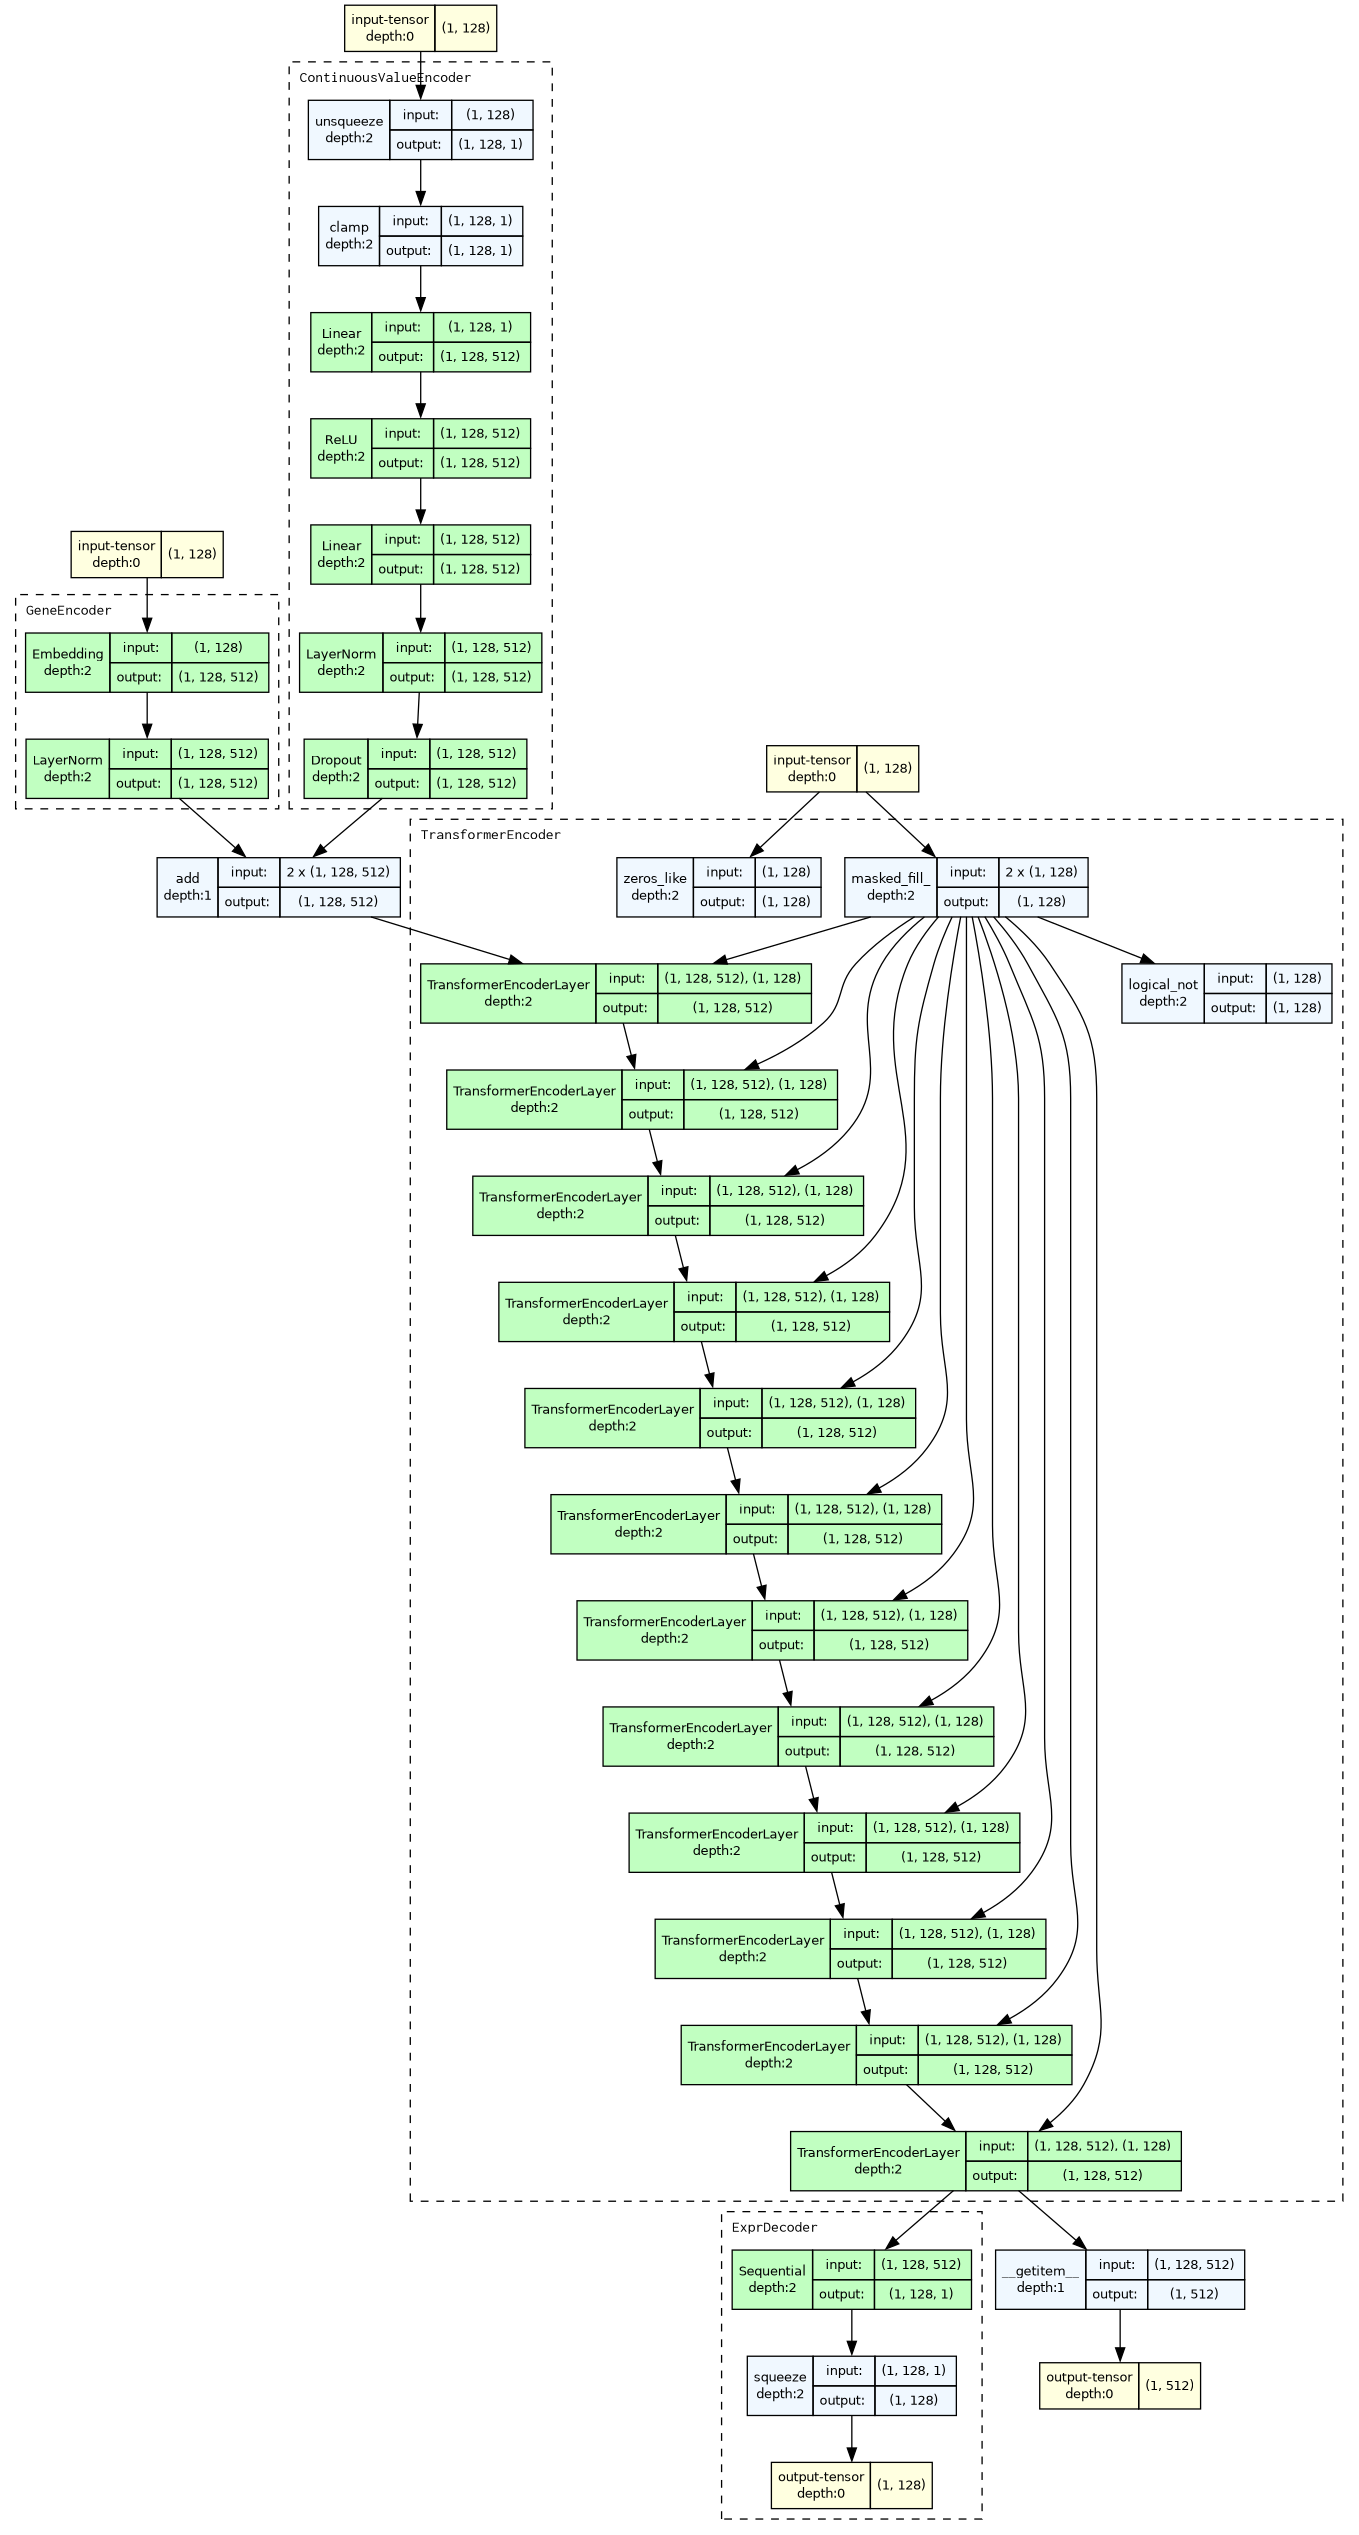

In [13]:
display(Image(filename="scGPT_architecture.png"))

## Geneformer

**Input**: gene token IDs (input_ids) ranked by normalized expression, and an attention mask.

- Counts are normalized to 10,000 per cell and divided by gene-specific medians.
- Expressed genes are ranked in descending order; only their token IDs are passed to the model.
- The attention mask is 1 for valid tokens and 0 for padding.
- CLS and EOS tokens are added to the sequence.

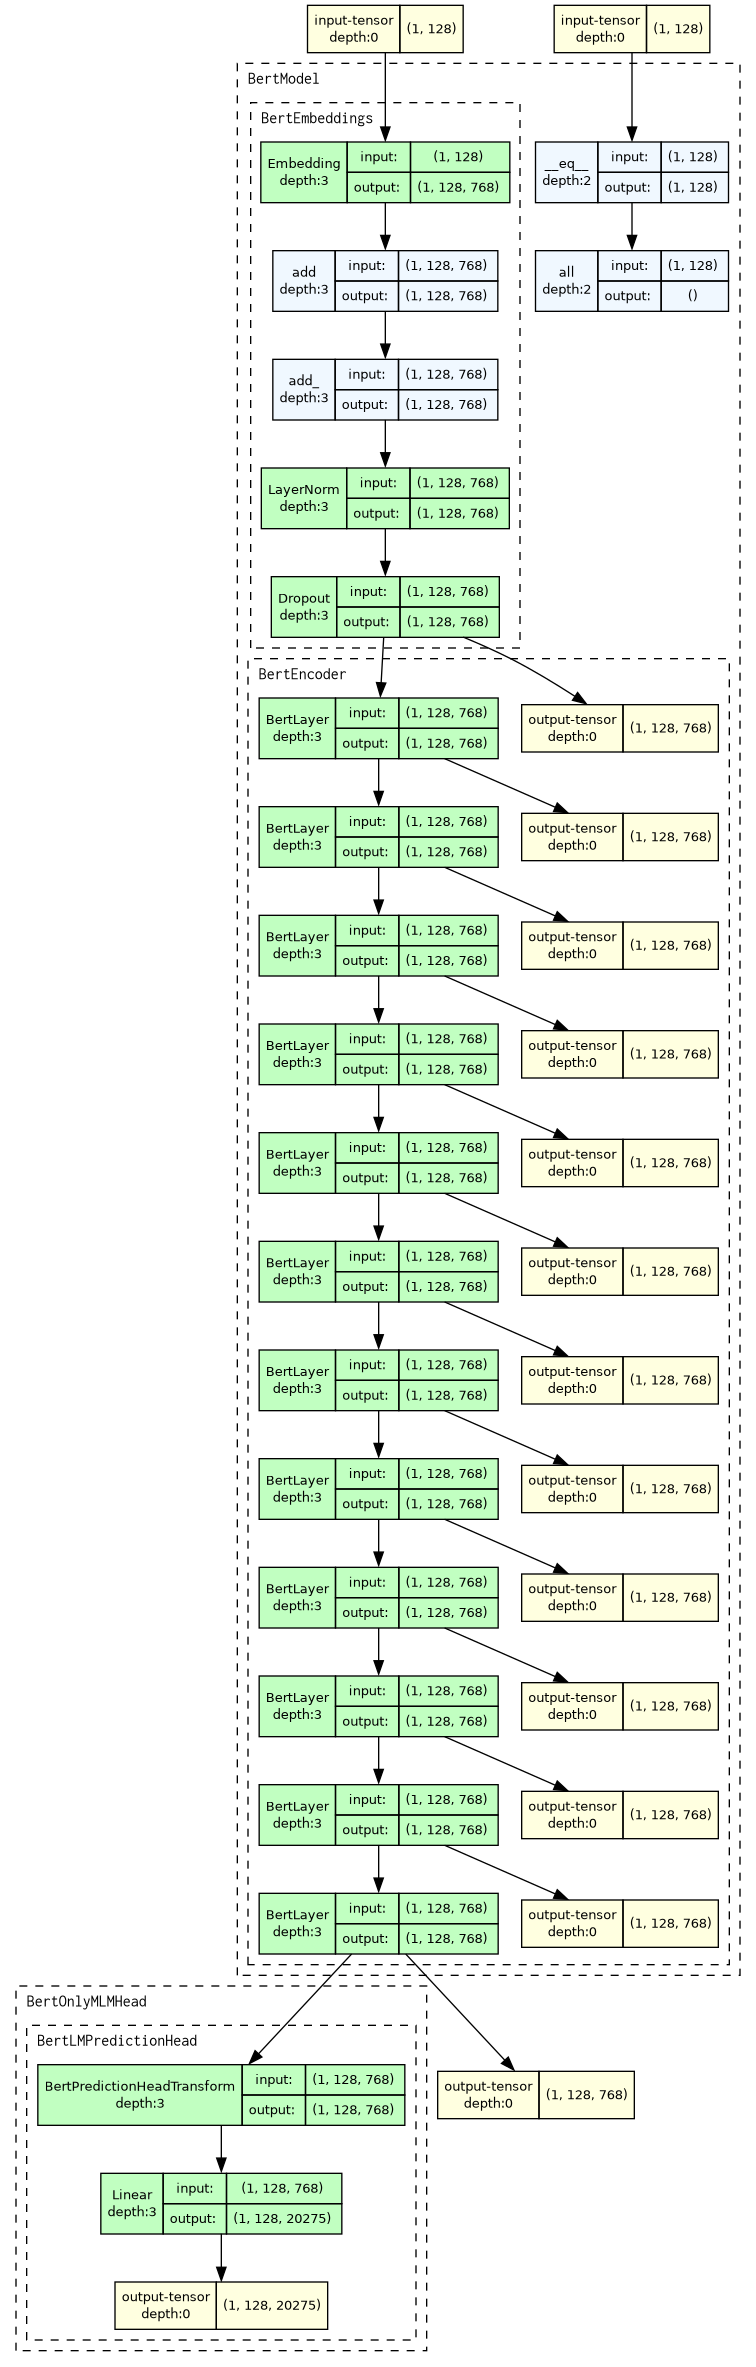

In [14]:
display(Image(filename="Geneformer_architecture.png"))